# 04. CPA로 AES-128 키 복구하기

CPA는 `HW(SBox[평문 XOR 키 후보])`와 각 시간 샘플의 Pearson 상관계수를 계산합니다. DPA와 달리 0부터 8까지의 해밍 무게 정보를 모두 사용합니다. 여기서는 합성 파형으로 계산을 익히고, 실제 측정 결과는 05 노트북에서 확인합니다.

## 첫 바이트 CPA

합성 AES 파형 420개를 만든 뒤 첫 번째 키 바이트의 후보 256개를 시험합니다. 각 후보가 만든 해밍 무게 벡터와 파형의 모든 시간 샘플 사이에서 상관계수를 구합니다. 후보별 최대 절댓값이 첫 바이트 점수입니다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cw_sca_tutorial.analysis import cpa_correlations, recover_key_cpa, welch_t_test
from cw_sca_tutorial.synthetic import make_aes_dataset

dataset = make_aes_dataset(trace_count=420)
traces, plaintexts, key = dataset.traces, dataset.plaintexts, dataset.key
correlations = cpa_correlations(traces, plaintexts, byte_index=0)
scores = np.max(np.abs(correlations), axis=1)
best = int(np.argmax(scores))
print(f"첫 바이트: 후보 0x{best:02x}, 정답 0x{key[0]:02x}")

첫 바이트: 후보 0x2b, 정답 0x2b


## 상관계수 heatmap

왼쪽 heatmap은 256개 후보의 상관계수를 시간축 전체에 표시합니다. 정답 후보는 첫 바이트가 처리되는 샘플에서 뚜렷한 피크를 만듭니다. 오른쪽 그래프에서는 정답과 가장 강한 오답의 상관 파형을 직접 비교합니다.

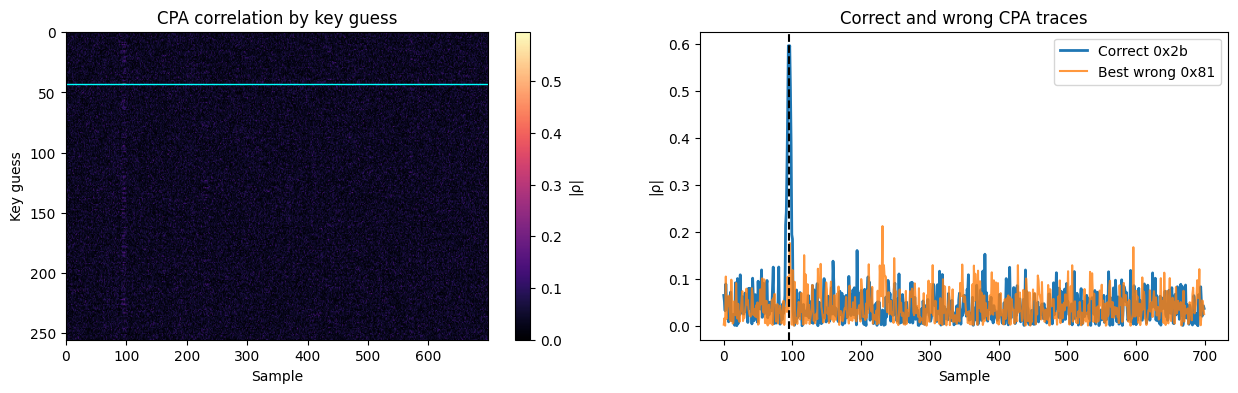

In [2]:
wrong = int(np.argsort(scores)[-2])
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
image = axes[0].imshow(np.abs(correlations), aspect="auto", cmap="magma", vmin=0)
axes[0].axhline(best, color="cyan", linewidth=1)
axes[0].set(title="CPA correlation by key guess", xlabel="Sample", ylabel="Key guess")
fig.colorbar(image, ax=axes[0], label="|ρ|")
axes[1].plot(np.abs(correlations[best]), label=f"Correct 0x{best:02x}", linewidth=2)
axes[1].plot(np.abs(correlations[wrong]), label=f"Best wrong 0x{wrong:02x}", alpha=.8)
axes[1].axvline(dataset.leakage_positions[0], color="black", linestyle="--")
axes[1].set(title="Correct and wrong CPA traces", xlabel="Sample", ylabel="|ρ|")
axes[1].legend()
plt.show()

## 파형 수에 따른 변화

사용하는 파형 수를 늘리면서 정답 후보와 가장 강한 오답의 최대 상관계수를 다시 계산합니다. 파형이 늘어날수록 두 점수가 어떻게 벌어지는지 확인합니다.

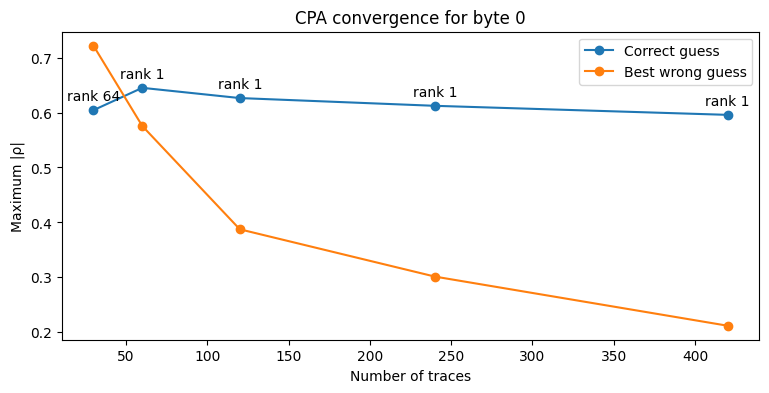

In [3]:
counts = [30, 60, 120, 240, 420]
true_scores, wrong_scores, ranks = [], [], []
for count in counts:
    corr = cpa_correlations(traces[:count], plaintexts[:count], byte_index=0)
    candidate_scores = np.max(np.abs(corr), axis=1)
    true_scores.append(candidate_scores[int(key[0])])
    wrong_scores.append(np.max(np.delete(candidate_scores, int(key[0]))))
    ranks.append(1 + int(np.sum(candidate_scores > candidate_scores[int(key[0])])))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(counts, true_scores, "o-", label="Correct guess")
ax.plot(counts, wrong_scores, "o-", label="Best wrong guess")
for x, y, rank in zip(counts, true_scores, ranks):
    ax.annotate(f"rank {rank}", (x, y), xytext=(0, 7), textcoords="offset points", ha="center")
ax.set(xlabel="Number of traces", ylabel="Maximum |ρ|", title="CPA convergence for byte 0")
ax.legend()
plt.show()

## 16바이트 키 복구

AES 첫 라운드에서는 각 바이트마다 `SBox[평문[i] XOR 키[i]]`를 계산합니다. 같은 CPA를 16번 적용해 전체 키를 구합니다.

정답 키:   2b7e151628aed2a6abf7158809cf4f3c
복구한 키: 2b7e151628aed2a6abf7158809cf4f3c
피크 샘플: [96, 130, 163, 197, 231, 265, 299, 333, 367, 402, 435, 470, 504, 537, 572, 606]


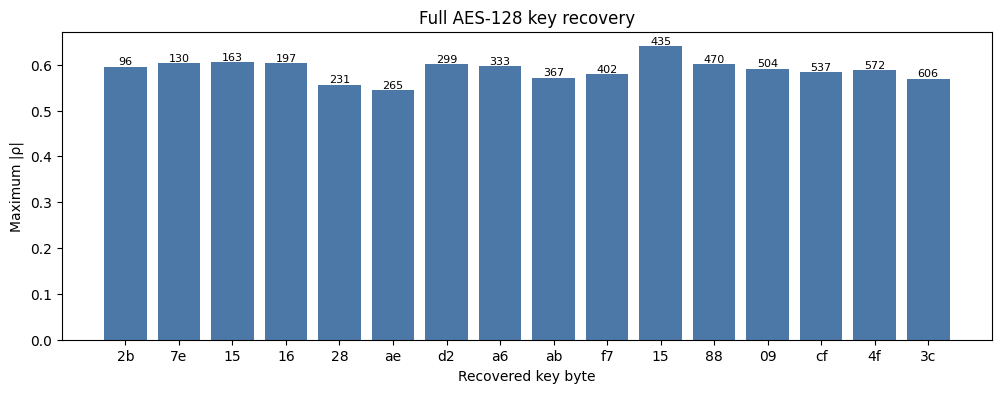

In [4]:
recovered, byte_scores, peak_samples = recover_key_cpa(traces, plaintexts)
print("정답 키:  ", bytes(key).hex())
print("복구한 키:", bytes(recovered).hex())
print("피크 샘플:", peak_samples.tolist())
assert np.array_equal(recovered, key)

fig, ax = plt.subplots(figsize=(12, 4))
bars = ax.bar(range(16), byte_scores, color="#4c78a8")
ax.set_xticks(range(16), [f"{value:02x}" for value in recovered])
ax.set(xlabel="Recovered key byte", ylabel="Maximum |ρ|", title="Full AES-128 key recovery")
for bar, sample in zip(bars, peak_samples):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), str(sample), ha="center", va="bottom", fontsize=8)
plt.show()